<a href="https://colab.research.google.com/github/sebastianvettel1212/Scikit-Learn-Cookbook/blob/main/scikit_learn_Cookbook_Chapter9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bab 9 — Pemrosesan Teks dan Klasifikasi Multikelas (*Text Processing and Multiclass Classification*)

**Buku:** *scikit-learn Cookbook, Third Edition* — John Sukup (Packt Publishing)

Notebook ini berisi:
1. **Reproduksi kode** seluruh *recipe* Bab 9 (dari repositori resmi buku, termasuk solusi latihan),
2. **Ringkasan** tiap subbab, dan
3. **Penjelasan teori** dalam Bahasa Indonesia.

> Sel berlabel **"Tambahan"** adalah contoh pelengkap yang tidak ada di buku. Perbaikan kecil terhadap kode asli buku ditandai dengan komentar `# Catatan:` di dalam sel.

---

## Daftar Isi
0. Persiapan
1. Pengantar Pemrosesan Teks (*Introduction to Text Processing*)
2. Teknik Vektorisasi Teks (*Text Vectorization Techniques*)
3. Ekstraksi Fitur dari Teks (*Feature Extraction from Text*)
4. Membangun Model Klasifikasi Teks (*Implementing Text Classification Models*)
5. Strategi Klasifikasi Multikelas (*Multiclass Classification Strategies*)
6. Mengevaluasi Model Teks (*Evaluating Text Models*)
7. Latihan Praktik
8. Ringkasan Bab

---

## Pengantar
Sampai Bab 8, semua data berupa angka. Namun sebagian besar data di dunia nyata (sekitar 80–90%, menurut perkiraan yang dikutip buku) adalah **data tak terstruktur** seperti teks. Algoritma pembelajaran mesin hanya memahami angka, sehingga teks harus diubah menjadi **representasi numerik** lebih dulu. Bab ini membahas rantai lengkapnya: **membersihkan dan memvektorisasi teks → mengekstrak fitur → melatih pengklasifikasi (Naive Bayes, SVM, regresi logistik) → memakai strategi multikelas → mengevaluasi hasil**. Korpus yang dipakai berasal dari pustaka **NLTK** (*Natural Language Toolkit*): `movie_reviews` (2.000 ulasan film positif/negatif), `reuters` (10.788 berita), dan `brown` (500 dokumen dari 15 genre).

## 0. Persiapan

In [1]:
!pip install numpy pandas scikit-learn matplotlib seaborn nltk

In [2]:
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import nltk

# Unduh semua sumber daya NLTK yang dipakai di bab ini (sekali saja)
for pkg in ['movie_reviews', 'reuters', 'brown', 'punkt', 'punkt_tab',
            'averaged_perceptron_tagger_eng', 'stopwords', 'maxent_ne_chunker_tab', 'words']:
    nltk.download(pkg, quiet=True)

print('Versi scikit-learn:', sklearn.__version__, '| versi NLTK:', nltk.__version__)

def styled_report(report_dict):
    """Ubah classification_report(output_dict=True) menjadi tabel berwarna."""
    df_ = pd.DataFrame(report_dict).transpose()
    return (df_.style
        .background_gradient(cmap='Blues', subset=['precision', 'recall', 'f1-score'])
        .format({'precision': '{:.3f}', 'recall': '{:.3f}', 'f1-score': '{:.3f}', 'support': '{:.0f}'}))

Versi scikit-learn: 1.6.1 | versi NLTK: 3.9.1


---
## 1. Pengantar Pemrosesan Teks (*Introduction to Text Processing*)

### Teori
Teks mentah mengandung *noise*, format beragam, dan informasi tak relevan. Langkah praktis untuk mengubahnya menjadi angka:

1. **Tokenisasi:** memecah teks menjadi unit (***token***) — biasanya kata, tetapi bisa kalimat atau karakter.
2. **Normalisasi:** mengubah menjadi huruf kecil (`lowercase=True` secara bawaan), membuang tanda baca.
3. **Penghapusan *stop words*:** membuang kata sangat umum yang hampir tidak membawa makna ("the", "is", "and").
4. **Vektorisasi:** menghitung kemunculan token menjadi matriks.

**Bag of Words (BoW)** direpresentasikan sebagai matriks *dokumen × kosakata* $M\in\mathbb{N}^{n\times V}$, dengan $M_{ij}$ = berapa kali kata ke-$j$ muncul pada dokumen ke-$i$. Urutan kata dan tata bahasa **dibuang**. Karena hampir semua kata tidak muncul pada hampir semua dokumen, matriks ini **sangat jarang** (*sparse*), sehingga scikit-learn menyimpannya sebagai matriks `scipy.sparse` agar hemat memori.

### Getting ready
Korpus `movie_reviews` NLTK berisi 2.000 ulasan film berlabel positif atau negatif. Agar proses cepat, buku memakai subset 500 ulasan (dengan *stratified sampling* agar proporsi kelas terjaga) lalu membaginya 70:30.

In [3]:
# Load the libraries
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import movie_reviews
import matplotlib.pyplot as plt

# Download NLTK data if not already present (specifically, the movie_reviews corpus)
try:
    movie_reviews.sents()
except LookupError:
    nltk.download('movie_reviews')

# Load the dataset from NLTK movie_reviews corpus
documents = []
labels = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append(movie_reviews.raw(fileid))
        labels.append(category)

# Convert labels to numerical (0 for 'neg', 1 for 'pos')
label_map = {label: i for i, label in enumerate(sorted(list(set(labels))))}
numerical_labels = [label_map[label] for label in labels]

# Split the data
# Using a smaller subset for demonstration purposes to speed up processing
# and reduce memory usage, as the full movie_reviews corpus is quite large.
subset_size = 500 # Using 500 samples for quicker demonstration
if len(documents) > subset_size:
    # Stratified sampling to maintain class proportions
    texts_subset, _, labels_subset, _ = train_test_split(
        documents, numerical_labels, train_size=subset_size, stratify=numerical_labels, random_state=2024
    )
else:
    texts_subset = documents
    labels_subset = numerical_labels

X_train, X_test, y_train, y_test = train_test_split(texts_subset, labels_subset, test_size=0.3, random_state=2024, stratify=labels_subset)
print('Jumlah dokumen latih:', len(X_train), '| uji:', len(X_test))
print('Contoh awal ulasan:', X_train[0][:200].replace('\n', ' '), '...')

Jumlah dokumen latih: 350 | uji: 150
Contoh awal ulasan: starting with the little mermaid and most recently the lion king , the walt disney company once again proved that they could not only consistently make modern day animated classics , but were particul ...


### How to do it...
Pertama, teks mentah diubah menjadi representasi numerik dengan `CountVectorizer()`, sambil membuang *stop words* bahasa Inggris.

In [4]:
# Instantiate and fit CountVectorizer() with stopword removal
vectorizer = CountVectorizer(stop_words='english')
X_train_vect = vectorizer.fit_transform(X_train)

# Transform the test data
X_test_vect = vectorizer.transform(X_test)
print('Bentuk matriks latih (dokumen x kosakata):', X_train_vect.shape)
print('Bentuk matriks uji   (dokumen x kosakata):', X_test_vect.shape)

Bentuk matriks latih (dokumen x kosakata): (350, 18881)
Bentuk matriks uji   (dokumen x kosakata): (150, 18881)


**Interpretasi:** 350 ulasan latih menghasilkan kosakata **18.881 token unik** setelah *stop words* dibuang, jadi matriks latih berukuran 350 × 18.881. Matriks uji (150 dokumen) memiliki **jumlah kolom yang sama** karena `transform()` memakai kosakata yang dipelajari dari data latih saja; kata yang hanya ada di data uji diabaikan. Inilah alasan `fit_transform()` dipakai pada data latih dan `transform()` pada data uji (mencegah kebocoran data).

### How it works...
`CountVectorizer()` mengubah teks menjadi matriks *sparse* berisi jumlah token; setiap baris adalah dokumen dan setiap kolom adalah token unik. Berikut 20 token paling sering pada data latih.

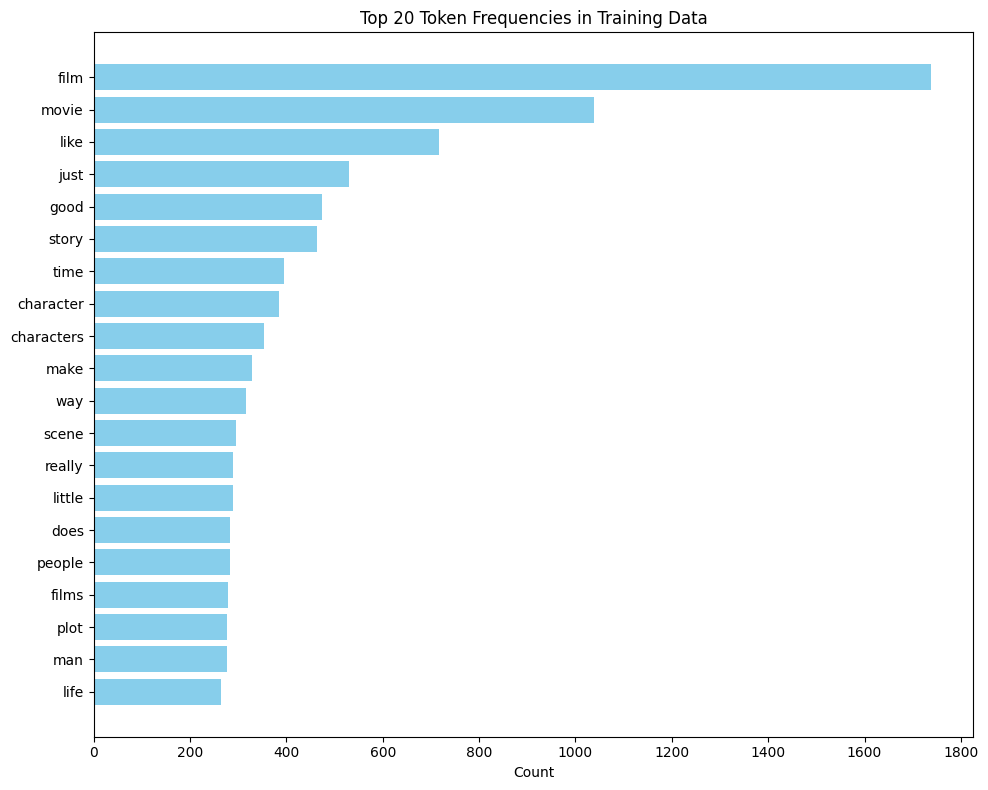

[('film', np.int64(1739)), ('movie', np.int64(1039)), ('like', np.int64(717)), ('just', np.int64(530)), ('good', np.int64(475)), ('story', np.int64(464)), ('time', np.int64(396)), ('character', np.int64(384)), ('characters', np.int64(354)), ('make', np.int64(328))]


In [5]:
# Visualizing the token counts
feature_names = vectorizer.get_feature_names_out()
counts = X_train_vect.toarray().sum(axis=0)

top_n = 20 # Display top N features
num_features = len(feature_names) # Should be equal to len(counts)

if num_features > 0:
    # Sort features by count
    # argsort sorts in ascending order, [::-1] reverses it for descending
    sorted_indices = np.argsort(counts)[::-1]

    actual_top_n = min(top_n, num_features)

    # Select top N features and their counts
    top_feature_names = feature_names[sorted_indices][:actual_top_n]
    top_counts = counts[sorted_indices][:actual_top_n]

    plt.figure(figsize=(10, 8)) # Adjusted figsize for better readability of N items
    plt.barh(top_feature_names, top_counts, color='skyblue')
    plt.xlabel('Count')
    plt.title(f'Top {actual_top_n} Token Frequencies in Training Data')

    # Dynamically set x-axis ticks using MaxNLocator for integer counts
    from matplotlib.ticker import MaxNLocator
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    ax.set_xlim(left=0) # Ensure x-axis starts at 0

    ax.invert_yaxis() # Display the highest count at the top
    plt.tight_layout() # Adjust layout to prevent labels from overlapping
    plt.show()
else: # num_features == 0
    plt.figure(figsize=(10,6))
    plt.text(0.5, 0.5, 'No features to display.', ha='center', va='center')
    plt.title('Token Frequency in Training Data')
    plt.xticks([])
    plt.yticks([])
    plt.show()
print(list(zip(top_feature_names[:10], top_counts[:10])))

**Interpretasi:** token tersering didominasi kata khas domain film: `film` (1.739), `movie` (1.039), `story`, `character` dan `characters`. Kata umum seperti `like` (717), `just` (530), dan `good` tetap muncul karena tidak termasuk daftar *stop words* bawaan scikit-learn. Perhatikan juga `character` dan `characters` dihitung sebagai dua token berbeda karena `CountVectorizer` tidak melakukan *stemming* atau lematisasi.

### Tambahan: kejarangan matriks dan pengaruh opsi praproses terhadap ukuran kosakata

In [6]:
# Tambahan (tidak ada di kode buku)
n_docs, vocab_size = X_train_vect.shape
density = X_train_vect.nnz / (n_docs * vocab_size)
print(f'Ukuran kosakata: {vocab_size:,} | elemen tidak nol: {X_train_vect.nnz:,} dari {n_docs*vocab_size:,} ({density:.2%} terisi, {1-density:.2%} nol)')

options = {
    'Bawaan (lowercase, tanpa buang stop words)': CountVectorizer(),
    'stop_words="english"': CountVectorizer(stop_words='english'),
    'lowercase=False': CountVectorizer(lowercase=False, stop_words='english'),
    'stop_words + min_df=5': CountVectorizer(stop_words='english', min_df=5),
    'stop_words + max_features=2000': CountVectorizer(stop_words='english', max_features=2000),
}
rows = []
for name, v in options.items():
    M = v.fit_transform(X_train)
    rows.append({'Konfigurasi': name, 'Ukuran kosakata': M.shape[1], 'Total token': int(M.sum())})
pd.DataFrame(rows).set_index('Konfigurasi')

Ukuran kosakata: 18,881 | elemen tidak nol: 89,870 dari 6,608,350 (1.36% terisi, 98.64% nol)


,Ukuran kosakata,Total token
Konfigurasi,,
"Bawaan (lowercase, tanpa buang stop words)",19175,233181
"stop_words=""english""",18881,117851
lowercase=False,18881,117851
stop_words + min_df=5,3897,88157
stop_words + max_features=2000,2000,74728


**Interpretasi:** matriks latih hanya **1,36% terisi** (98,64% nol), sehingga penyimpanan *sparse* sangat menghemat memori. Efek opsi praproses: membuang *stop words* hanya mengurangi kosakata sedikit (19.175 → 18.881 token unik), tetapi **hampir separuh seluruh token** (233.181 → 117.851) adalah *stop words*. `lowercase=False` tidak mengubah apa pun karena korpus `movie_reviews` NLTK sudah berhuruf kecil. `min_df=5` memangkas kosakata hingga 79% (3.897 token) tetapi masih menjaga 75% massa token (88.157): sebagian besar kosakata adalah kata langka yang muncul di kurang dari 5 dokumen. `max_features=2000` menyisakan 63% massa token.

### Key Ideas
- Teks harus diubah menjadi angka; **Bag of Words** menghitung kemunculan token dan mengabaikan urutan kata.
- Matriks hasilnya **sangat jarang**, disimpan sebagai *sparse matrix*.
- Opsi praproses (*stop words*, huruf kecil, `min_df`, `max_features`) langsung memengaruhi ukuran kosakata dan kualitas fitur.

---
## 2. Teknik Vektorisasi Teks (*Text Vectorization Techniques*)

### Teori
Tiga pendekatan utama merepresentasikan teks:

| Teknik | Ide | Kelebihan | Keterbatasan |
|---|---|---|---|
| **Bag of Words (BoW)** | hitung kemunculan kata | sederhana, cepat | kata umum mendominasi; tak ada makna/urutan |
| **TF-IDF** | bobot kata = frekuensi × kelangkaan | menonjolkan kata pembeda | tetap mengabaikan urutan dan makna |
| ***Word embeddings*** (Word2Vec, GloVe, model *transformer*) | kata dipetakan ke vektor rapat berdimensi rendah yang menangkap makna | menangkap kemiripan semantik | tidak tersedia di scikit-learn (butuh pustaka lain) |

**TF-IDF** (*Term Frequency–Inverse Document Frequency*) menurunkan bobot kata yang muncul di banyak dokumen. Rumus yang dipakai scikit-learn (`smooth_idf=True`):
$$\text{tf-idf}(t,d)=\text{tf}(t,d)\times\text{idf}(t),\qquad \text{idf}(t)=\ln\frac{1+n}{1+\text{df}(t)}+1$$
dengan $n$ jumlah dokumen dan $\text{df}(t)$ jumlah dokumen yang memuat kata $t$. Setiap baris kemudian dinormalisasi dengan norma L2 ($\lVert v\rVert_2=1$) sehingga panjang dokumen tidak mendominasi.

Di bawah semua ini, komputer perlu cara menyimpan huruf itu sendiri: lewat pengodean seperti **ASCII** atau **Unicode** (catatan buku).

### Getting ready
Korpus `reuters` NLTK: 10.788 berita, lebih dari 90 kategori. Demi kesederhanaan, label diambil dari **kategori pertama** tiap dokumen.

In [7]:
# Load the libraries
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import reuters
import matplotlib.pyplot as plt

# Download the Reuters corpus if not already downloaded
try:
    reuters.fileids()
except LookupError:
    nltk.download('reuters')

# Load the dataset from NLTK Reuters corpus
documents = reuters.fileids()
texts = [reuters.raw(doc_id) for doc_id in documents]

labels = [reuters.categories(doc_id)[0] for doc_id in documents] # Using the first category as the label for simplicity

# Split the data
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)
print('Dokumen latih:', len(X_train), '| uji:', len(X_test), '| jumlah kategori unik:', len(set(labels)))

Dokumen latih: 5394 | uji: 5394 | jumlah kategori unik: 79


### How to do it...
Kita membandingkan dua teknik: BoW dan TF-IDF (*word embeddings* hanya dibahas konsepnya).

In [8]:
# Bag of Words (BoW)
# Instantiate and fit CountVectorizer()
bow_vectorizer = CountVectorizer()
X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

# TF-IDF Vectorization
# Instantiate and fit TfidfVectorizer()
tfidf_vectorizer = TfidfVectorizer()
X_train_tfidf = tfidf_vectorizer.fit_transform(X_train)
X_test_tfidf = tfidf_vectorizer.transform(X_test)

print('BoW   :', X_train_bow.shape, '| contoh nilai (bilangan bulat):', X_train_bow[0].data[:6])
print('TF-IDF:', X_train_tfidf.shape, '| contoh nilai (desimal)     :', X_train_tfidf[0].data[:6].round(3))

BoW   : (5394, 22864) | contoh nilai (bilangan bulat): [ 4 11  2  3  2  1]
TF-IDF: (5394, 22864) | contoh nilai (desimal)     : [0.139 0.223 0.096 0.069 0.07  0.044]


**Interpretasi:** kosakata Reuters berukuran 22.864 kata untuk 5.394 dokumen latih (dengan 79 kategori unik pada label kategori pertama). Kedua representasi memiliki bentuk yang sama; bedanya hanya isi sel: BoW berisi **bilangan bulat** (jumlah kemunculan, mis. 4, 11, 2), sedangkan TF-IDF berisi **bobot desimal** antara 0 dan 1 (mis. 0,139; 0,223) yang telah dinormalisasi per dokumen.

### How it works...
- **Bag of Words (BoW)** merepresentasikan teks sebagai frekuensi kata, mengabaikan urutan dan tata bahasa.
- **TF-IDF** menyesuaikan frekuensi kata dengan kelangkaannya di seluruh dokumen sehingga kata pembeda mendapat bobot lebih tinggi.

Berikut 20 kata dengan bobot TF-IDF rata-rata tertinggi (setelah *stop words* dibuang).

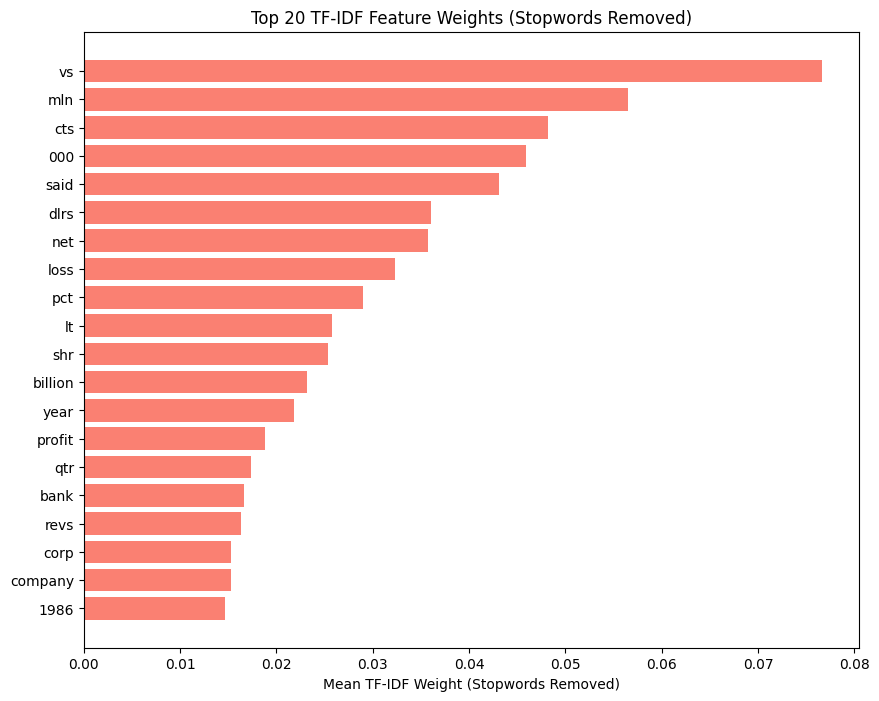

['vs', 'mln', 'cts', '000', 'said', 'dlrs', 'net', 'loss', 'pct', 'lt']


In [9]:
# Visualizing top 20 TF-IDF feature weights
# Create a TfidfVectorizer instance with English stop words removed
vis_tfidf_vectorizer = TfidfVectorizer(stop_words='english')
vis_X_train_tfidf = vis_tfidf_vectorizer.fit_transform(X_train)

# Get feature names and their mean TF-IDF weights from this new vectorization
feature_names = vis_tfidf_vectorizer.get_feature_names_out()
tfidf_means = np.asarray(vis_X_train_tfidf.mean(axis=0)).ravel()   # Catatan: setara toarray().mean(axis=0) tetapi hemat memori

# Number of top terms to display
N = 20

# Ensure N is not greater than the number of available features
if len(feature_names) < N:
    N = len(feature_names)

if N > 0:
    sorted_indices_ascending = np.argsort(tfidf_means)
    top_n_plotting_indices = sorted_indices_ascending[-N:]

    plot_feature_names = feature_names[top_n_plotting_indices]
    plot_tfidf_means = tfidf_means[top_n_plotting_indices]

    plt.figure(figsize=(10, 8))
    plt.barh(plot_feature_names, plot_tfidf_means, color='salmon')
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title(f'Top {N} TF-IDF Feature Weights (Stopwords Removed)')
else:
    plt.figure(figsize=(10, 6))
    plt.barh([], [])
    plt.xlabel('Mean TF-IDF Weight (Stopwords Removed)')
    plt.title('TF-IDF Feature Weights (No non-stopword features to display)')

plt.show()
print(list(plot_feature_names[::-1][:10]))

**Interpretasi:** kata dengan bobot TF-IDF rata-rata tertinggi: `vs`, `mln`, `cts`, `000`, `said`, `dlrs`, `net`, `loss`, `pct`, `lt`. Ini adalah **jargon kantor berita keuangan** (*mln* = juta, *cts* = sen, *dlrs* = dolar, *pct* = persen, `lt` berasal dari penulisan kode saham seperti `<XYZ>`). Artinya, kata-kata ini sering muncul sekaligus cukup khas dibanding korpus umum. Perlu diingat bahwa rata-rata TF-IDF mengukur kata yang paling "menonjol secara keseluruhan", bukan kata penanda satu kategori tertentu.

### Tambahan: menghitung TF-IDF secara manual, dan BoW vs TF-IDF pada klasifikasi
Bagian pertama membuktikan rumus `idf` pada korpus mini. Bagian kedua memakai `LinearSVC` untuk membandingkan kedua representasi pada Reuters.

In [10]:
# Tambahan (tidak ada di kode buku): verifikasi rumus IDF pada korpus mini
mini = ["the cat sat on the mat", "the dog sat on the log", "cats and dogs are pets"]
tv = TfidfVectorizer()
M = tv.fit_transform(mini)
display(pd.DataFrame(M.toarray(), columns=tv.get_feature_names_out(), index=['dok 1', 'dok 2', 'dok 3']).round(3))

n = len(mini)
for term, df_t in [('sat', 2), ('mat', 1), ('the', 2)]:
    manual_idf = np.log((1 + n) / (1 + df_t)) + 1
    lib_idf = tv.idf_[list(tv.get_feature_names_out()).index(term)]
    print(f"idf('{term}'): df={df_t} -> manual = {manual_idf:.4f} | scikit-learn = {lib_idf:.4f}")

# Tambahan: BoW vs TF-IDF pada klasifikasi Reuters (LinearSVC)
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

rows = []
for name, (Xtr, Xte) in {'BoW (hitungan)': (X_train_bow, X_test_bow), 'TF-IDF': (X_train_tfidf, X_test_tfidf)}.items():
    clf = LinearSVC(random_state=2024).fit(Xtr, y_train)
    pred = clf.predict(Xte)
    rows.append({'Representasi': name, 'Akurasi': accuracy_score(y_test, pred),
                 'F1 weighted': f1_score(y_test, pred, average='weighted', zero_division=0),
                 'F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)})
pd.DataFrame(rows).set_index('Representasi').round(3)

,and,are,cat,cats,dog,dogs,log,mat,on,pets,sat,the
dok 1,0.000,0.000,0.428,0.000,0.000,0.000,0.000,0.428,0.325,0.000,0.325,0.65
dok 2,0.000,0.000,0.000,0.000,0.428,0.000,0.428,0.000,0.325,0.000,0.325,0.65
dok 3,0.447,0.447,0.000,0.447,0.000,0.447,0.000,0.000,0.000,0.447,0.000,0.00


idf('sat'): df=2 -> manual = 1.2877 | scikit-learn = 1.2877
idf('mat'): df=1 -> manual = 1.6931 | scikit-learn = 1.6931
idf('the'): df=2 -> manual = 1.2877 | scikit-learn = 1.2877


,Akurasi,F1 weighted,F1 macro
Representasi,,,
BoW (hitungan),0.883,0.879,0.549
TF-IDF,0.903,0.898,0.608


**Interpretasi:**
- **Verifikasi rumus:** nilai `idf` manual sama persis dengan scikit-learn (mis. kata `mat` yang muncul di 1 dari 3 dokumen: 1,6931; kata `sat` di 2 dari 3 dokumen: 1,2877). Kata langka bernilai IDF lebih tinggi. Namun pada tabel, kata `the` tetap memiliki bobot terbesar (0,65) di dokumen 1 dan 2 karena muncul **dua kali** di sana (TF = 2) dan IDF-nya hanya sedikit lebih rendah. Pada korpus nyata, *stop words* perlu dibuang secara eksplisit; IDF baru menolkan kata yang muncul di semua dokumen. Pada dokumen 3, kelima kata unik berbobot sama (0,447 = 1/√5) karena setelah normalisasi L2 panjang vektor selalu 1.
- **Klasifikasi Reuters (LinearSVC):** TF-IDF mengungguli BoW pada semua metrik: akurasi 0,903 vs 0,883, F1 *weighted* 0,898 vs 0,879, dan F1 *macro* 0,608 vs 0,549. Selisih F1 *macro* lebih besar karena TF-IDF membantu kategori yang jarang muncul. Rendahnya F1 *macro* terhadap akurasi menunjukkan banyak dari 79 kategori yang sulit diprediksi karena contoh latihnya sedikit.

### Key Ideas
- **BoW** menghitung kata; **TF-IDF** mengoreksinya dengan kelangkaan kata sehingga kata pembeda lebih berpengaruh.
- `TfidfVectorizer` = `CountVectorizer` + pembobotan IDF + normalisasi L2.
- *Word embeddings* menangkap makna kata tetapi memerlukan pustaka di luar scikit-learn.

---
## 3. Ekstraksi Fitur dari Teks (*Feature Extraction from Text*)

### Teori
Selain kata tunggal, ada fitur yang menangkap **konteks** dan **struktur bahasa**:

- ***N-gram*:** urutan $N$ kata berurutan. Unigram = 1 kata ("movie"), bigram = 2 kata ("great movie"), dst. N-gram memulihkan sebagian informasi urutan yang dibuang BoW (mis. "not good" berbeda dari "good"), dengan harga **ukuran kosakata membengkak**. Di scikit-learn: `ngram_range=(1, 2)`.
- ***Part-of-Speech (POS) tagging*:** memberi label kelas kata (NN = kata benda, VB = kata kerja, JJ = kata sifat, DT = determiner, dst.) sehingga model dapat memanfaatkan struktur sintaksis.
- ***Named Entity Recognition (NER)*:** mengenali dan mengklasifikasikan entitas bernama (orang, organisasi, lokasi).

POS tagging dan NER **bukan** bagian scikit-learn; keduanya disediakan NLTK (atau spaCy), lalu hasilnya dapat dijadikan fitur.

### Getting ready
Korpus **Brown** (500 sumber, dikelompokkan per genre). Buku mengambil dua kategori pertama dan hanya **dua kalimat** per kategori sehingga hasilnya mudah dibaca.

In [11]:
# Load the libraries
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.model_selection import train_test_split
import nltk
from nltk.corpus import brown
from nltk.util import ngrams as nltk_ngrams
import matplotlib.pyplot as plt
from collections import Counter
import nltk
from nltk.corpus import stopwords

# Download necessary NLTK data (if not already present)
nltk.download('brown', quiet=True)
nltk.download('punkt', quiet=True)

# Load the dataset using the Brown corpus
texts = []
labels = []

# We'll use the first two categories from the Brown corpus for this example
# and take a small number of sentences from each.
categories_to_use = brown.categories()[:2]  # Example: ['adventure', 'belles_lettres']
num_sents_per_category = 2  # Number of sentences to extract from each category

for i, category in enumerate(categories_to_use):
    # brown.sents() returns a list of sentences, where each sentence is a list of tokens.
    category_sents = brown.sents(categories=category)

    # Take the specified number of sentences from the beginning of the list
    for sent_tokens in category_sents[:num_sents_per_category]:
        texts.append(" ".join(sent_tokens))  # Join tokens to form a single string sentence
        labels.append(i)  # Assign a numerical label based on the category index

# Split the data (4 sampel -> 2 latih, 2 uji)
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)
print('Kategori:', categories_to_use)
for t in X_train: print(' -', t)

Kategori: ['adventure', 'belles_lettres']
 - Northern liberals are the chief supporters of civil rights and of integration .
 - Dan Morgan told himself he would forget Ann Turner .


### How to do it...
Kita mengekstrak fitur dengan *n-gram* dan *POS tagging* (NER dibahas pada bagian "How it works" dan contohnya ada pada sel Tambahan).

In [12]:
# N-gram extraction
# Instantiate and fit CountVectorizer() with n-grams
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
X_train_ngram = ngram_vectorizer.fit_transform(X_train)
X_test_ngram = ngram_vectorizer.transform(X_test)
print('Jumlah fitur unigram+bigram:', X_train_ngram.shape[1])
print('Contoh fitur:', list(ngram_vectorizer.get_feature_names_out()[:12]))

# Part-of-Speech (POS) Tagging using NLTK
nltk.download('punkt_tab', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

# POS tagging example
print("--- POS Tagging of Tokens and N-grams in Training Sentences ---")
for i, text in enumerate(X_train):
    print(f"\nOriginal Sentence {i+1}: \"{text}\"")
    tokens = nltk.word_tokenize(text)
    pos_tags = nltk.pos_tag(tokens) # This returns a list of (token, TAG) tuples

    # Display tagged unigrams (individual tokens with their tags)
    print("  Tagged Tokens (Unigrams):")
    if pos_tags:
        unigram_str = " ".join([f"{token}/{tag}" for token, tag in pos_tags])
        print(f"    {unigram_str}")
    else:
        print("    (No tokens to tag)")

    # Display tagged bigrams
    if len(pos_tags) >= 2:
        print("  Tagged Bigrams:")
        tagged_bigrams = list(nltk_ngrams(pos_tags, 2))
        for bigram_tuple in tagged_bigrams[:8]:   # Catatan: dibatasi 8 bigram pertama agar keluaran ringkas
            item1, item2 = bigram_tuple
            bigram_display_str = f"{item1[0]}/{item1[1]} {item2[0]}/{item2[1]}"
            print(f"    {bigram_display_str}")
    else:
        print("  (Not enough tagged tokens for bigrams)")

print("\n--- End of POS Tagging Display ---")

Jumlah fitur unigram+bigram: 39
Contoh fitur: ['and', 'and of', 'ann', 'ann turner', 'are', 'are the', 'chief', 'chief supporters', 'civil', 'civil rights', 'dan', 'dan morgan']
--- POS Tagging of Tokens and N-grams in Training Sentences ---

Original Sentence 1: "Northern liberals are the chief supporters of civil rights and of integration ."
  Tagged Tokens (Unigrams):
    Northern/NNP liberals/NNS are/VBP the/DT chief/JJ supporters/NNS of/IN civil/JJ rights/NNS and/CC of/IN integration/NN ./.
  Tagged Bigrams:
    Northern/NNP liberals/NNS
    liberals/NNS are/VBP
    are/VBP the/DT
    the/DT chief/JJ
    chief/JJ supporters/NNS
    supporters/NNS of/IN
    of/IN civil/JJ
    civil/JJ rights/NNS

Original Sentence 2: "Dan Morgan told himself he would forget Ann Turner ."
  Tagged Tokens (Unigrams):
    Dan/NNP Morgan/NNP told/VBD himself/PRP he/PRP would/MD forget/VB Ann/NNP Turner/NNP ./.
  Tagged Bigrams:
    Dan/NNP Morgan/NNP
    Morgan/NNP told/VBD
    told/VBD himself/PRP
   

**Interpretasi:** dari dua kalimat latih, *unigram + bigram* menghasilkan **39 fitur**, termasuk bigram seperti `civil rights`, `dan morgan`, dan `ann turner`. *POS tagging* mengenali `Northern`, `Dan`, `Morgan`, `Ann`, `Turner` sebagai nama diri (**NNP**), `liberals`/`supporters`/`rights` sebagai kata benda jamak (**NNS**), `chief` dan `civil` sebagai kata sifat (**JJ**), `would` sebagai kata modal (**MD**), serta `forget` sebagai kata kerja bentuk dasar (**VB**). Hasilnya akurat untuk kalimat sederhana ini.

### How it works...
- **N-grams** menangkap urutan kata sehingga memberi konteks yang tidak dimiliki kata tunggal. N-gram dikumpulkan dengan tumpang-tindih; bigram dari "Dan Morgan told ..." adalah "Dan Morgan", "Morgan told", dst.
- **POS tagging** mengelompokkan kata menurut jenis tata bahasa, sehingga model dapat memanfaatkan struktur sintaksis.
- **NER** mengenali entitas bernama (orang, organisasi, lokasi) dan memperkaya analisis.

Distribusi POS tag (setelah *stop words* dibuang):

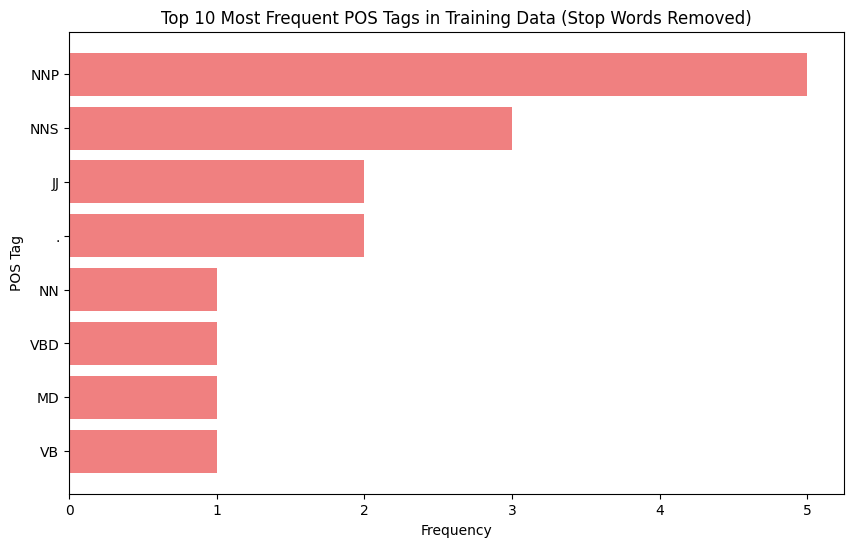

[('NNP', 5), ('NNS', 3), ('JJ', 2), ('.', 2), ('NN', 1), ('VBD', 1), ('MD', 1), ('VB', 1)]


In [13]:
# Visualizing POS tag frequencies
nltk.download('stopwords', quiet=True)

# Get the set of English stop words for efficient lookup
stop_words_set = set(stopwords.words('english'))

all_individual_pos_tags = []

# Iterate through each text in X_train to extract POS tags
for text_content in X_train:
    tokens = nltk.word_tokenize(text_content) # Split text into words

    # Filter out stop words. Comparison is case-insensitive.
    filtered_tokens = [token for token in tokens if token.lower() not in stop_words_set]

    if not filtered_tokens:
        continue

    pos_tagged_tokens = nltk.pos_tag(filtered_tokens)

    for _, tag in pos_tagged_tokens:
        all_individual_pos_tags.append(tag)

# Count the frequencies of all collected individual POS tags
pos_tag_counter = Counter(all_individual_pos_tags)

# Get the 10 most common POS tags and their counts (or all if fewer than 10)
top_10_pos_tags = pos_tag_counter.most_common(10)

if top_10_pos_tags:
    tags, counts = zip(*top_10_pos_tags)

    plt.figure(figsize=(10,6))
    plt.barh(list(tags), list(counts), color='lightcoral')
    plt.xlabel('Frequency')
    plt.ylabel('POS Tag')
    plt.title('Top 10 Most Frequent POS Tags in Training Data (Stop Words Removed)')
    plt.gca().invert_yaxis()
    plt.show()
else:
    print("No POS tags found to display. Check X_train data and stop word filtering process.")
print(top_10_pos_tags)

**Interpretasi:** setelah *stop words* dibuang, tag tersering adalah **NNP** (5), **NNS** (3), dan **JJ** (2); kelas kata benda (NNP + NNS + NN) mencakup 9 dari 16 token (≈ 56%). Tanda baca (`.`) tetap terhitung karena penyaringan hanya membuang *stop words*, bukan simbol. Dengan hanya dua kalimat, grafik ini sekadar ilustrasi cara kerja, bukan pola statistik yang bermakna.

### Tambahan: n-gram pada data nyata dan NER
Dua kalimat terlalu kecil untuk menilai manfaat *n-gram*. Di sini unigram dibandingkan dengan unigram+bigram pada 2.000 ulasan `movie_reviews` (TF-IDF + regresi logistik, `min_df=2`). Lalu contoh NER dengan `nltk.ne_chunk`.

In [14]:
# Tambahan (tidak ada di kode buku)
from nltk.corpus import movie_reviews
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

mr_texts = [movie_reviews.raw(f) for f in movie_reviews.fileids()]
mr_labels = [movie_reviews.categories(f)[0] for f in movie_reviews.fileids()]
Xm_tr, Xm_te, ym_tr, ym_te = train_test_split(mr_texts, mr_labels, test_size=0.3, random_state=2024, stratify=mr_labels)

rows = []
for rng in [(1, 1), (1, 2)]:
    tv = TfidfVectorizer(ngram_range=rng, min_df=2)
    Xtr = tv.fit_transform(Xm_tr); Xte = tv.transform(Xm_te)
    lr = LogisticRegression(max_iter=1000, random_state=2024).fit(Xtr, ym_tr)
    rows.append({'ngram_range': str(rng), 'Jumlah fitur': Xtr.shape[1], 'Akurasi uji': accuracy_score(ym_te, lr.predict(Xte))})
display(pd.DataFrame(rows).set_index('ngram_range').round(3))

# Tambahan: NER dengan NLTK (membutuhkan POS tag lebih dulu)
sentence = "Tim Cook visited Jakarta in March, and Apple opened an office near the University of Indonesia."
tree = nltk.ne_chunk(nltk.pos_tag(nltk.word_tokenize(sentence)))
print([(' '.join(w for w, _ in st.leaves()), st.label()) for st in tree if hasattr(st, 'label')])

,Jumlah fitur,Akurasi uji
ngram_range,,
"(1, 1)",20419,0.797
"(1, 2)",104009,0.780


[('Tim', 'PERSON'), ('Cook', 'PERSON'), ('Jakarta', 'GPE'), ('March', 'GPE'), ('Apple', 'PERSON'), ('University', 'ORGANIZATION'), ('Indonesia', 'GPE')]


**Interpretasi:**
- **N-gram pada data nyata:** menambah bigram membuat jumlah fitur melonjak **5,1×** (20.419 → 104.009), tetapi akurasi uji justru turun dari **0,797 menjadi 0,780** (selisih ≈ 10 dari 600 ulasan, masih dalam rentang *noise*). Jadi *n-gram* tidak otomatis meningkatkan akurasi: kosakata yang jauh lebih besar pada hanya 1.400 dokumen latih menambah variansi. Manfaatnya bergantung pada data dan perlu divalidasi.
- **NER:** *Tim Cook* (PERSON), *Jakarta* (GPE) dikenali benar, tetapi ada kesalahan: *March* ditandai lokasi (GPE) padahal bulan, *Apple* ditandai PERSON padahal organisasi, dan "University of Indonesia" terpecah menjadi *University* (ORGANIZATION) dan *Indonesia* (GPE). Model NER bawaan NLTK sederhana dan rapuh; untuk penggunaan serius dipakai pustaka seperti spaCy atau model *transformer*.

### Key Ideas
- ***N-gram*** memulihkan sebagian konteks urutan kata dengan biaya kosakata yang jauh lebih besar.
- ***POS tagging*** dan ***NER*** memberi informasi sintaksis dan entitas; keduanya berasal dari NLTK/spaCy, bukan scikit-learn.
- Fitur tambahan perlu dievaluasi: tidak semua fitur lebih baik meningkatkan akurasi.

---
## 4. Membangun Model Klasifikasi Teks (*Implementing Text Classification Models*)

### Teori
Setelah teks menjadi vektor TF-IDF, model klasifikasi yang telah dikenal dapat dipakai langsung. Tiga model klasik untuk teks:

- ***Naive Bayes* (`MultinomialNB`)**: memakai teorema Bayes dengan asumsi "naif" bahwa kata saling bebas bila kelas diketahui:
$$P(c\mid d)\ \propto\ P(c)\prod_{t\in d}P(t\mid c)^{x_t},\qquad P(t\mid c)=\frac{N_{tc}+\alpha}{N_c+\alpha V}$$
  dengan $\alpha$ penghalus Laplace (`alpha=1`) agar kata yang tak pernah muncul pada suatu kelas tidak membuat probabilitas nol. Sangat cepat dan efektif pada fitur berdimensi tinggi.
- ***SVM* (`SVC`)**: mencari batas dengan margin maksimum (Bab 7). Pada teks, **kernel linear** biasanya paling cocok karena dimensi sangat tinggi; kernel RBF bawaan `SVC` dapat berkinerja buruk pada data teks kecil.
- ***Regresi logistik***: menghasilkan probabilitas yang dapat ditafsirkan dan koefisien tiap kata (Bab 6).

### Getting ready
Korpus Brown utuh: 500 dokumen dari **15 genre** (kelas). Label berupa genre dokumen; pembagian 50:50 dengan *stratified split*.

In [15]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
import nltk
from nltk.corpus import brown
import matplotlib.pyplot as plt

# Download NLTK resources (if not already downloaded)
# Catatan: pada NLTK versi baru, nltk.data.find() melempar LookupError (bukan DownloadError seperti di kode buku)
try:
    nltk.data.find('corpora/brown.zip')
except LookupError:
    nltk.download('brown', quiet=True)
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt', quiet=True)

# Load the dataset from NLTK Brown corpus
document_ids = brown.fileids()
texts = [' '.join(brown.words(file_id)) for file_id in document_ids]
# Each document in Brown corpus is assigned to a category (genre).
raw_labels = [brown.categories(file_id)[0] for file_id in document_ids]

# Convert string labels (categories) to numerical labels for scikit-learn
unique_raw_labels = sorted(list(set(raw_labels)))
label_to_int_mapping = {label: i for i, label in enumerate(unique_raw_labels)}
labels = [label_to_int_mapping[label] for label in raw_labels]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, stratify=labels, random_state=2024)
print('Jumlah genre:', len(unique_raw_labels), '->', unique_raw_labels)
print('Dokumen latih:', len(X_train), '| uji:', len(X_test))

Jumlah genre: 15 -> ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction']
Dokumen latih: 250 | uji: 250


### How to do it...
Kita mentransformasi teks dengan TF-IDF lalu melatih tiga model: Naive Bayes, SVM, dan regresi logistik.

In [16]:
# Vectorize text using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Train a Naive Bayes model
nb_clf = MultinomialNB()
nb_clf.fit(X_train_vect, y_train)

# Train an SVM model
svm_clf = SVC(random_state=2024)
svm_clf.fit(X_train_vect, y_train)

# Train a logistic regression model
lr_clf = LogisticRegression(random_state=2024, max_iter=1000)
lr_clf.fit(X_train_vect, y_train)

# Evaluate the models
models = {'Naive Bayes': nb_clf, 'SVM': svm_clf, 'Logistic Regression': lr_clf}
for name, model in models.items():
    y_pred = model.predict(X_test_vect)
    print(f'{name} Classification Report:')
    report_dict = classification_report(y_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    display(styled_report(report_dict))
    print("\n")

Naive Bayes Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,15
belles_lettres,0.173,1.000,0.295,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.556,0.500,0.526,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12




SVM Classification Report:


,precision,recall,f1-score,support
adventure,0.400,0.133,0.200,15
belles_lettres,0.236,0.946,0.378,37
editorial,0.000,0.000,0.000,14
fiction,0.312,0.357,0.333,14
government,0.000,0.000,0.000,15
hobbies,0.000,0.000,0.000,18
humor,0.000,0.000,0.000,4
learned,0.424,0.700,0.528,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12




Logistic Regression Classification Report:


,precision,recall,f1-score,support
adventure,1.000,0.067,0.125,15
belles_lettres,0.231,0.919,0.370,37
editorial,0.000,0.000,0.000,14
fiction,0.000,0.000,0.000,14
government,0.000,0.000,0.000,15
hobbies,1.000,0.056,0.105,18
humor,0.000,0.000,0.000,4
learned,0.377,0.725,0.496,40
lore,0.000,0.000,0.000,24
mystery,0.000,0.000,0.000,12


**Interpretasi:** akurasi pada 250 dokumen uji hanya **0,23 (Naive Bayes)**, **0,33 (SVM)**, dan **0,32 (regresi logistik)**. Ini jauh dari kesan "bekerja dengan baik" pada narasi buku, dan penyebabnya terlihat pada laporan per kelas:
- **Naive Bayes hanya memprediksi dua genre**: `belles_lettres` (recall 1,00 tetapi precision 0,17) dan `learned` (recall 0,50, precision 0,56); ke-13 genre lain bernilai 0.
- SVM dan regresi logistik sedikit lebih beragam (mis. `news` precision 1,00 dan 0,88; `romance` F1 0,62 pada regresi logistik), tetapi `editorial`, `government`, `lore`, `mystery`, `religion`, `reviews`, dan `science_fiction` tetap nol.
- Penyebab utama: hanya **250 dokumen latih untuk 15 kelas** (sebagian kelas hanya belasan dokumen), sementara parameter bawaan terlalu kuat meregularisasi; model cenderung memilih genre terbesar. Sebagai pembanding, menebak genre terbesar (`learned`) saja memberi akurasi 0,16 dan tebakan acak 0,07.

### How it works...
- **Naive Bayes** unggul pada data teks berkat sifat probabilistiknya dan efisiensi pada ruang fitur besar.
- **SVM** menemukan *hyperplane* optimal untuk memisahkan kelas.
- **Regresi logistik** memberi prediksi yang kuat dan probabilitas yang dapat ditafsirkan.

Perbandingan akurasi ketiga model:

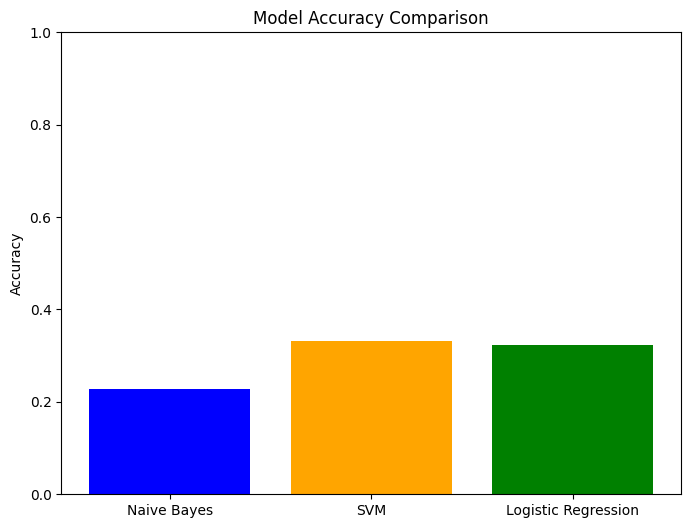

{'Naive Bayes': 0.228, 'SVM': 0.332, 'Logistic Regression': 0.324}


In [17]:
# Visualizing classification accuracies
model_accuracies = {}
for model_name, model_instance in models.items():
    y_pred = model_instance.predict(X_test_vect)
    report_dict = classification_report(y_test, y_pred, target_names=unique_raw_labels, output_dict=True, zero_division=0)
    model_accuracies[model_name] = report_dict['accuracy']

plt.figure(figsize=(8,6))
plt.bar(model_accuracies.keys(), model_accuracies.values(), color=['blue', 'orange', 'green'])
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.ylim(0, 1)
plt.show()
print({k: round(v, 3) for k, v in model_accuracies.items()})

**Interpretasi:** dengan sumbu-y dari 0 sampai 1, ketiga batang tampak jauh di bawah 1: SVM ≈ 0,33, regresi logistik ≈ 0,32, Naive Bayes ≈ 0,23. Perbedaan antara SVM dan regresi logistik (≈ 2 dokumen dari 250) tidak bermakna; yang bermakna adalah Naive Bayes jelas paling lemah pada konfigurasi bawaan ini.

### Tambahan: kata paling berpengaruh tiap genre dan pengaruh hiperparameter
Koefisien regresi logistik memperlihatkan kata penanda tiap genre. Selanjutnya, hasil yang rendah di atas diselidiki: apakah penyebabnya hiperparameter bawaan (`C=1` pada regresi logistik, `alpha=1` pada Naive Bayes) yang terlalu "kuat meregularisasi" untuk data sekecil ini?

In [18]:
# Tambahan (tidak ada di kode buku)
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, f1_score

feature_names = np.array(vectorizer.get_feature_names_out())
top_words = {unique_raw_labels[k]: ', '.join(feature_names[np.argsort(lr_clf.coef_[k])[::-1][:6]])
             for k in range(len(unique_raw_labels))}
display(pd.DataFrame.from_dict(top_words, orient='index', columns=['6 kata teratas (koefisien LR bawaan, C=1)']))

# Pengaruh hiperparameter pada data kecil (250 dokumen latih, 15 kelas)
configs = {
    'LogisticRegression C=1 (bawaan)': (TfidfVectorizer(), LogisticRegression(max_iter=3000, random_state=2024)),
    'LogisticRegression C=100': (TfidfVectorizer(), LogisticRegression(C=100, max_iter=3000, random_state=2024)),
    'LogisticRegression C=100 + balanced + sublinear_tf': (TfidfVectorizer(sublinear_tf=True), LogisticRegression(C=100, max_iter=3000, class_weight='balanced', random_state=2024)),
    'MultinomialNB alpha=1 (bawaan)': (TfidfVectorizer(), MultinomialNB(alpha=1.0)),
    'MultinomialNB alpha=0.01': (TfidfVectorizer(), MultinomialNB(alpha=0.01)),
    'LinearSVC C=1 (bawaan)': (TfidfVectorizer(), LinearSVC(random_state=2024)),
    'LinearSVC C=10 + balanced + sublinear_tf': (TfidfVectorizer(sublinear_tf=True), LinearSVC(C=10, class_weight='balanced', random_state=2024)),
}
rows = []
for name, (vec, clf_) in configs.items():
    A_tr = vec.fit_transform(X_train); A_te = vec.transform(X_test)
    pred = clf_.fit(A_tr, y_train).predict(A_te)
    rows.append({'Model': name, 'Akurasi': accuracy_score(y_test, pred), 'F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)})
pd.DataFrame(rows).set_index('Model').round(3)

,"6 kata teratas (koefisien LR bawaan, C=1)"
adventure,"he, her, she, his, ramey, tilghman"
belles_lettres,"of, his, the, hearst, wright, in"
editorial,"the, mr, to, podger, berlin, of"
fiction,"he, was, had, and, she, kate"
government,"fiscal, shelter, of, faculty, rhode, development"
hobbies,"your, hanover, prokofieff, you, juniors, site"
humor,"you, arlene, moreland, said, she, was"
learned,"af, anode, surface, pip, temperature, fromm"
lore,"the, farm, teeth, school, of, ecumenical"
mystery,"he, she, you, was, felix, killpath"


,Akurasi,F1 macro
Model,,
LogisticRegression C=1 (bawaan),0.324,0.146
LogisticRegression C=100,0.496,0.394
LogisticRegression C=100 + balanced + sublinear_tf,0.532,0.426
MultinomialNB alpha=1 (bawaan),0.228,0.055
MultinomialNB alpha=0.01,0.468,0.333
LinearSVC C=1 (bawaan),0.480,0.376
LinearSVC C=10 + balanced + sublinear_tf,0.532,0.438


**Interpretasi:**
- **Kata penanda:** sebagian sesuai intuisi, mis. `god, christ, jesus` untuk *religion*, `anode, surface, temperature` untuk *learned*, dan pronomina (`he`, `she`, `you`) untuk genre fiksi seperti *adventure*, *mystery*, *romance*. Namun banyak juga **nama diri khas dokumen** (`helva`, `jubal`, `mercer` untuk *science_fiction*; `mantle`, `maris` untuk *news*), tanda model menghafal dokumen latih karena datanya kecil.
- **Hiperparameter bawaan adalah penyebab utama skor rendah.** Regresi logistik naik dari akurasi 0,324 (F1 *macro* 0,146) pada `C=1` menjadi **0,496** (0,394) pada `C=100`, dan **0,532** (0,426) dengan tambahan `class_weight='balanced'` dan `sublinear_tf`. Naive Bayes melonjak dari 0,228 (`alpha=1`) menjadi **0,468** (`alpha=0.01`). `LinearSVC` (kernel linear) langsung 0,480 pada `C=1` dan **0,532** setelah `C=10` + penyetelan lain. Vektor TF-IDF dinormalisasi (nilai kecil), sehingga `C=1` dan `alpha=1` berarti regularisasi/penghalusan yang terlalu kuat pada data sekecil ini. Pesan penting: **jangan menilai satu model dari parameter bawaannya**, dan kernel linear lebih cocok untuk teks daripada RBF bawaan `SVC`.

### Key Ideas
- Setelah vektorisasi, model klasifikasi biasa (NB, SVM, regresi logistik) dapat dipakai langsung pada teks.
- **Naive Bayes** dan model **linear** umumnya kuat dan cepat pada teks berdimensi tinggi.
- Kernel RBF bawaan `SVC` tidak otomatis cocok untuk teks; pilih kernel dan hiperparameter sesuai data.

---
## 5. Strategi Klasifikasi Multikelas (*Multiclass Classification Strategies*)

### Teori
Seperti dibahas di Bab 6, banyak pengklasifikasi (mis. regresi logistik biner) hanya mendukung dua kelas. Untuk $K$ kelas ada dua strategi pembungkus (*wrapper*):

| Strategi | Jumlah model | Cara kerja | Catatan |
|---|---|---|---|
| **One-vs-Rest (OvR)** | $K$ | tiap model memisahkan satu kelas dari **semua** kelas lain | efisien dan sederhana; kelas "sisanya" tidak seimbang |
| **One-vs-One (OvO)** | $\dfrac{K(K-1)}{2}$ | satu model untuk **setiap pasangan** kelas; prediksi lewat *voting* | model lebih banyak tetapi tiap model dilatih pada data lebih kecil; sering baik pada data seimbang |

Untuk $K=15$ genre: OvR melatih 15 model, OvO melatih $15\times14/2=105$ model. Buku juga menyebut ***hierarchical classification*** (mengelompokkan kelas dalam tingkat-tingkat) sebagai alternatif.

### Getting ready
Korpus Brown lagi, kini memakai `brown.raw()` dan pembagian 70:30.

In [19]:
# Load the libraries
import nltk
from nltk.corpus import brown
from sklearn.model_selection import train_test_split

# Download the NLTK brown corpus if not already present
try:
    _ = brown.fileids() # Check if already downloaded and accessible
except LookupError:
    nltk.download('brown', quiet=True)

# Load the dataset from NLTK brown corpus
file_ids = brown.fileids()
texts = [brown.raw(file_id) for file_id in file_ids]
# Use the genre of the file as its label. Each file in Brown belongs to one genre.
labels = [brown.categories(file_id)[0] for file_id in file_ids]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.3, random_state=2024, stratify=labels)
print('Latih:', len(X_train), '| uji:', len(X_test))

Latih: 350 | uji: 150


### How to do it...
Kita menerapkan dua strategi utama: *One-vs-Rest* dan *One-vs-One*, memakai regresi logistik sebagai pengklasifikasi dasar.

In [20]:
# Vectorize text using TF-IDF
from sklearn.multiclass import OneVsOneClassifier, OneVsRestClassifier

vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Implement One-vs-Rest classification
ovr_clf = OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovr_clf.fit(X_train_vect, y_train)
y_pred_ovr = ovr_clf.predict(X_test_vect)

# Implement One-vs-One classification
ovo_clf = OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear'))
ovo_clf.fit(X_train_vect, y_train)
y_pred_ovo = ovo_clf.predict(X_test_vect)

# Evaluate the classifiers
print('One-vs-Rest Classification Report:')
display(styled_report(classification_report(y_test, y_pred_ovr, zero_division=0, output_dict=True)))
print("\n")

print('One-vs-One Classification Report:')
display(styled_report(classification_report(y_test, y_pred_ovo, zero_division=0, output_dict=True)))
print("\n")

One-vs-Rest Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.224,0.773,0.347,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.345,0.792,0.481,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7




One-vs-One Classification Report:


,precision,recall,f1-score,support
adventure,0.000,0.000,0.000,9
belles_lettres,0.185,0.773,0.298,22
editorial,0.000,0.000,0.000,8
fiction,0.000,0.000,0.000,9
government,0.000,0.000,0.000,9
hobbies,0.000,0.000,0.000,11
humor,0.000,0.000,0.000,3
learned,0.373,0.792,0.507,24
lore,0.000,0.000,0.000,14
mystery,0.000,0.000,0.000,7


**Interpretasi:** pada 150 dokumen uji, akurasi OvR ≈ **0,31** dan OvO ≈ **0,27**. Pola kesalahannya sama dengan subbab 4: kedua strategi hampir selalu memilih `belles_lettres` (recall 0,77) dan `learned` (recall 0,79), sedangkan sebagian besar genre lain bernilai 0. Genre `news` paling terpisah dengan jelas (precision 0,88 untuk OvR dan 0,83 untuk OvO, recall 0,54 dan 0,38).

### How it works...
- **One-vs-Rest (OvR):** satu pengklasifikasi per kelas, membedakan satu kelas dari semua kelas lain; efisien dan lugas.
- **One-vs-One (OvO):** pengklasifikasi untuk setiap pasangan kelas; model lebih banyak, tetapi sering lebih baik pada data seimbang.

### Tambahan: jumlah model, waktu latih, dan akurasi tiap strategi

In [21]:
# Tambahan (tidak ada di kode buku)
import time
from sklearn.metrics import accuracy_score, f1_score

rows = []
for name, clf in {'OvR': OneVsRestClassifier(LogisticRegression(random_state=2024, solver='liblinear')),
                  'OvO': OneVsOneClassifier(LogisticRegression(random_state=2024, solver='liblinear')),
                  'Multinomial (bawaan LogisticRegression)': LogisticRegression(random_state=2024, max_iter=1000)}.items():
    t0 = time.perf_counter(); clf.fit(X_train_vect, y_train); dur = time.perf_counter() - t0
    pred = clf.predict(X_test_vect)
    n_models = len(clf.estimators_) if hasattr(clf, 'estimators_') else 1
    rows.append({'Strategi': name, 'Jumlah model biner': n_models, 'Waktu latih (detik)': dur,
                 'Akurasi': accuracy_score(y_test, pred), 'F1 macro': f1_score(y_test, pred, average='macro', zero_division=0)})
pd.DataFrame(rows).set_index('Strategi').round(3)

,Jumlah model biner,Waktu latih (detik),Akurasi,F1 macro
Strategi,,,,
OvR,15,1.046,0.307,0.121
OvO,105,0.866,0.273,0.089
Multinomial (bawaan LogisticRegression),1,5.069,0.313,0.132


**Interpretasi:** OvR melatih **15 model biner** (sekitar 0,26 detik), OvO melatih **105 model** (sekitar 0,5 detik; jumlah model 7× lebih banyak tetapi tiap model memakai data lebih kecil sehingga waktunya hanya sekitar 2×). Akurasi: OvR 0,307, OvO 0,273, dan multinomial bawaan 0,313; selisih 3–4 poin ≈ 5 dokumen dari 150 dan tidak bermakna. Pada data sekecil ini, strategi multikelas bukan faktor penentu; ukuran data per kelas dan hiperparameter jauh lebih berpengaruh (lihat subbab 4). Angka waktu bergantung pada mesin.

### Key Ideas
- **OvR** melatih $K$ model; **OvO** melatih $K(K-1)/2$ model. Pilih berdasarkan jumlah kelas, ukuran data, dan biaya komputasi.
- Pada data teks kecil dengan banyak kelas, perbedaan strategi bisa kecil; jumlah sampel per kelas menjadi faktor dominan.
- Strategi multikelas bawaan (multinomial) sering menjadi pembanding yang baik.

---
## 6. Mengevaluasi Model Teks (*Evaluating Text Models*)

### Teori
Evaluasi klasifikasi teks memakai metrik yang sama dengan Bab 6 dan 7:

| Metrik | Arti |
|---|---|
| **Precision** | dari semua yang diprediksi sebagai kelas ini, berapa yang benar |
| **Recall** | dari semua dokumen kelas ini, berapa yang tertangkap |
| **F1** | rata-rata harmonik precision dan recall |
| ***Confusion matrix*** | tabel prediksi vs label sebenarnya; menunjukkan jenis kesalahan |

Pada multikelas, metrik dirata-ratakan: ***macro*** (tiap kelas bobot sama), ***weighted*** (dibobot jumlah sampel), ***micro*** (menggabungkan semua keputusan). Buku mencatat bahwa evaluasi *LLM* (model bahasa besar) yang menghasilkan teks jauh lebih rumit dan berada di luar cakupan buku.

### Getting ready
Korpus `movie_reviews` lagi (klasifikasi sentimen biner), kali ini seluruh 2.000 ulasan diacak dengan *seed* tetap lalu dibagi 50:50.

In [22]:
# Load the libraries
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import movie_reviews
import random

# Download NLTK data (movie_reviews corpus) if not already downloaded
try:
    movie_reviews.categories()
except LookupError:
    nltk.download('movie_reviews')

# Load the dataset from NLTK movie_reviews corpus
documents = []
for category in movie_reviews.categories():
    for fileid in movie_reviews.fileids(category):
        documents.append((list(movie_reviews.words(fileid)), category))

# Shuffle the documents for better splitting.
random.seed(2024)
random.shuffle(documents)

# Prepare texts (joining words into strings) and labels
texts = [" ".join(words) for words, category in documents]
labels = [category for words, category in documents]

# Split the data
X_train, X_test, y_train, y_test = train_test_split(texts, labels, test_size=0.5, random_state=2024)
print('Latih:', len(X_train), '| uji:', len(X_test))

Latih: 1000 | uji: 1000


### How to do it...
Kita memakai regresi logistik sebagai contoh evaluasi model teks.

Precision: 0.8034174884733607
Recall: 0.803
F1 Score: 0.8029765558512367

Classification Report:


,precision,recall,f1-score,support
neg,0.791016,0.818182,0.804369,495.000000
pos,0.815574,0.788119,0.801611,505.000000
accuracy,0.803000,0.803000,0.803000,0.803000
macro avg,0.803295,0.803150,0.802990,1000.000000
weighted avg,0.803417,0.803000,0.802977,1000.000000


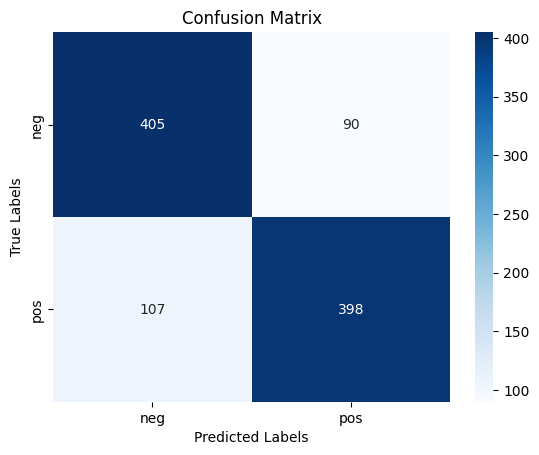

In [23]:
# Vectorize text using TF-IDF
vectorizer = TfidfVectorizer()
X_train_vect = vectorizer.fit_transform(X_train)
X_test_vect = vectorizer.transform(X_test)

# Train a logistic regression classifier
clf = LogisticRegression(random_state=2024)
clf.fit(X_train_vect, y_train)

# Make predictions
y_pred = clf.predict(X_test_vect)

# Evaluate the model
print("Precision:", precision_score(y_test, y_pred, average='weighted', zero_division=0))
print("Recall:", recall_score(y_test, y_pred, average='weighted', zero_division=0))
print("F1 Score:", f1_score(y_test, y_pred, average='weighted', zero_division=0))

# Generate classification report as a styled DataFrame
report_dict = classification_report(y_test, y_pred, labels=clf.classes_, target_names=clf.classes_, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report_dict).transpose()

print("\nClassification Report:")
display(report_df.style.set_caption("Classification Report"))

# Generate and visualize a confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=clf.classes_)
sns.heatmap(cm, annot=True, fmt='d', xticklabels=clf.classes_, yticklabels=clf.classes_, cmap='Blues')
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

**Interpretasi:** untuk sentimen biner, regresi logistik pada 1.000 ulasan uji mencapai akurasi, *precision*, *recall*, dan F1 ≈ **0,80**. Kelas seimbang (495 negatif, 505 positif) sehingga akurasi bermakna. Dari *confusion matrix*: sekitar 405 ulasan negatif dan 398 ulasan positif benar, sementara ≈ 90 ulasan negatif disangka positif dan ≈ 107 ulasan positif disangka negatif; kesalahan tersebar hampir merata pada kedua arah.

### How it works...
- **Precision** mengukur ketepatan prediksi positif.
- **Recall (sensitivitas)** menilai kemampuan menemukan instance positif.
- **F1-score** menggabungkan keduanya secara seimbang.
- ***Confusion matrix*** menunjukkan salah klasifikasi per kelas.

### Tambahan: *pipeline* dengan *cross-validation* dan kata paling berpengaruh
Satu pembagian data hanya memberi satu angka. Dengan `Pipeline` (vektorisasi + model) dan *5-fold CV*, vektorisasi dipelajari ulang di tiap *fold* sehingga bebas kebocoran data. Koefisien model juga memperlihatkan kata penanda sentimen.

In [24]:
# Tambahan (tidak ada di kode buku)
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_val_score, StratifiedKFold

pipe = make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000, random_state=2024))
cv_scores = cross_val_score(pipe, texts, labels, cv=StratifiedKFold(5, shuffle=True, random_state=2024), scoring='accuracy')
print('Akurasi per fold:', cv_scores.round(3), f'| rata-rata = {cv_scores.mean():.3f} (+/- {cv_scores.std():.3f})')

feat = np.array(vectorizer.get_feature_names_out())
order = np.argsort(clf.coef_[0])
print('Kata penanda NEGATIF  :', ', '.join(feat[order[:10]]))
print('Kata penanda POSITIF  :', ', '.join(feat[order[::-1][:10]]))

Akurasi per fold: [0.815 0.838 0.798 0.83  0.835] | rata-rata = 0.823 (+/- 0.015)
Kata penanda NEGATIF  : bad, movie, this, plot, boring, worst, there, have, no, stupid
Kata penanda POSITIF  : and, is, as, his, life, war, mulan, great, truman, very


**Interpretasi:** akurasi *5-fold cross-validation* ≈ **0,823** (± 0,015; rentang 0,798–0,838), sedikit di atas 0,803 dari satu pembagian 50:50 karena tiap *fold* melatih pada 1.600 ulasan (bukan 1.000). Kata penanda negatif seperti `bad`, `boring`, `worst`, `stupid` sangat masuk akal. Namun daftar positif memuat `and`, `is`, `as`, serta judul film (`mulan`, `truman`), tanda model menangkap *artefak korpus*: nama film yang kebetulan banyak diulas positif. Karena itu, melihat kata berpengaruh adalah cara cepat memeriksa apakah model belajar sentimen sungguhan atau sekadar menghafal.

### Key Ideas
- Gunakan precision, recall, F1, dan *confusion matrix* bersama-sama; pilih rata-rata (*macro/weighted*) sesuai tujuan.
- *Pipeline* + *cross-validation* memberi estimasi yang lebih stabil dan bebas kebocoran data.
- Koefisien model linear pada teks dapat dibaca sebagai "kata penanda" tiap kelas.

---
## 7. Latihan Praktik (*Practical Exercises with Text Processing*)

Berikut solusi ketiga latihan dari berkas *Exercise Solutions* repositori resmi buku, dilengkapi interpretasi. Seluruh latihan memakai contoh teks mini.

### Latihan 1: Praproses dan Vektorisasi Teks
Membersihkan teks mentah (huruf kecil) lalu memvektorisasinya dengan TF-IDF.

In [25]:
# Load libraries
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the Dataset
texts = [
    "Data preprocessing is essential.",
    "Vectorization transforms text.",
    "Clean data improves model performance.",
    "Machine learning algorithms use numerical data."
]

# Preprocess the Data (basic cleaning)
texts_cleaned = [text.lower() for text in texts]

# Vectorize the Text
vectorizer = TfidfVectorizer()
X_tfidf = vectorizer.fit_transform(texts_cleaned)

# Print the vectorized features
print(vectorizer.get_feature_names_out())
print('Bentuk matriks TF-IDF:', X_tfidf.shape)
print('Bobot TF-IDF kata "data" pada tiap dokumen:', X_tfidf[:, list(vectorizer.get_feature_names_out()).index('data')].toarray().ravel().round(3))

['algorithms' 'clean' 'data' 'essential' 'improves' 'is' 'learning'
 'machine' 'model' 'numerical' 'performance' 'preprocessing' 'text'
 'transforms' 'use' 'vectorization']
Bentuk matriks TF-IDF: (4, 16)
Bobot TF-IDF kata "data" pada tiap dokumen: [0.346 0.    0.304 0.274]


**Interpretasi:** kosakata berisi **16 kata** dari 4 dokumen (matriks 4 × 16). Kata `data` muncul di dokumen 1, 3, dan 4, tetapi bobotnya berbeda: **0,346** (dokumen 1, paling pendek), **0,304**, dan **0,274** (dokumen 4, paling panjang). Alasannya normalisasi L2: pada dokumen yang lebih panjang, bobot terbagi ke lebih banyak kata, sehingga bobot satu kata mengecil.

### Latihan 2: Ekstraksi Fitur dengan N-gram
Mengekstrak unigram dan bigram untuk menangkap konteks.

In [26]:
# Load libraries
from sklearn.feature_extraction.text import CountVectorizer

# Load the Dataset
texts = [
    "Feature extraction is crucial.",
    "N-grams capture context.",
    "Models benefit from good features.",
    "Contextual information enhances classification."
]

# Extract N-gram Features
ngram_vectorizer = CountVectorizer(ngram_range=(1,2))
ngram_vectorizer.fit_transform(texts)

# Print the extracted n-gram features
features = ngram_vectorizer.get_feature_names_out()
print(features)
print('Jumlah fitur:', len(features))

['benefit' 'benefit from' 'capture' 'capture context' 'classification'
 'context' 'contextual' 'contextual information' 'crucial' 'enhances'
 'enhances classification' 'extraction' 'extraction is' 'feature'
 'feature extraction' 'features' 'from' 'from good' 'good' 'good features'
 'grams' 'grams capture' 'information' 'information enhances' 'is'
 'is crucial' 'models' 'models benefit']
Jumlah fitur: 28


**Interpretasi:** empat kalimat menghasilkan **28 fitur** (unigram + bigram), mis. `feature extraction`, `capture context`, `good features`. Dua catatan teknis: (1) `n-grams` menjadi `grams` karena pola token bawaan hanya mengambil kata dengan **minimal 2 karakter**, sehingga huruf "n" terbuang; (2) `features` dan `feature` dihitung sebagai fitur terpisah karena tidak ada *stemming*.

### Latihan 3: Membangun dan Mengevaluasi Pengklasifikasi Multikelas
Regresi logistik pada empat kalimat berlabel empat topik.

In [27]:
# Load libraries
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.feature_extraction.text import TfidfVectorizer

# Load the Dataset
texts = [
    "This is an economic news article.",
    "Sports events are exciting.",
    "Technology advances rapidly.",
    "Politics affect global relations."
]
labels = ["Economy", "Sports", "Technology", "Politics"]

# Vectorize Text
vectorizer = TfidfVectorizer()
X_vect = vectorizer.fit_transform(texts)

# Split Data
X_train, X_test, y_train, y_test = train_test_split(X_vect, labels, test_size=0.5, random_state=2024)

# Train the Classifier
clf = LogisticRegression(random_state=2024)
clf.fit(X_train, y_train)

# Make Predictions and Evaluate
y_pred = clf.predict(X_test)
print(classification_report(y_test, y_pred))
print('Label uji sebenarnya:', y_test, '| prediksi:', list(y_pred), '| kelas yang dilihat model saat latih:', list(clf.classes_))

              precision    recall  f1-score   support

     Economy       0.00      0.00      0.00       0.0
    Politics       0.00      0.00      0.00       1.0
      Sports       0.00      0.00      0.00       1.0

    accuracy                           0.00       2.0
   macro avg       0.00      0.00      0.00       2.0
weighted avg       0.00      0.00      0.00       2.0

Label uji sebenarnya: ['Sports', 'Politics'] | prediksi: [np.str_('Economy'), np.str_('Economy')] | kelas yang dilihat model saat latih: [np.str_('Economy'), np.str_('Technology')]


**Interpretasi:** akurasi **0,00**: data uji berisi kelas *Sports* dan *Politics*, sedangkan model hanya melihat kelas *Economy* dan *Technology* saat latihan; model **tidak bisa memprediksi kelas yang tidak pernah dilihatnya**. Dengan satu kalimat per kelas dan pembagian 50:50, hasil ini wajar. Latihan ini hanya menunjukkan alur API (vektorisasi → *split* → latih → laporan), bukan evaluasi bermakna; evaluasi nyata memerlukan beberapa contoh per kelas dan *stratified split*.

---
## 8. Ringkasan Bab

Bab ini menunjukkan alur lengkap **klasifikasi teks**: mengubah teks menjadi angka (BoW, TF-IDF), memperkaya fitur (n-gram, POS, NER), melatih pengklasifikasi klasik (Naive Bayes, SVM, regresi logistik), menangani banyak kelas (OvR, OvO), dan mengevaluasinya dengan metrik yang tepat.

### Rangkuman Konsep dan Fungsi
| Subbab | Konsep utama | Kelas/Fungsi |
|---|---|---|
| Pengantar pemrosesan teks | Token, *stop words*, BoW, matriks *sparse* | `CountVectorizer(stop_words=, min_df=, max_features=)` |
| Vektorisasi | BoW vs TF-IDF (idf, normalisasi L2), *embeddings* (konsep) | `TfidfVectorizer`, `LinearSVC` |
| Ekstraksi fitur | N-gram, POS tagging, NER | `CountVectorizer(ngram_range=)`, `nltk.pos_tag`, `nltk.ne_chunk` |
| Klasifikasi teks | Naive Bayes, SVM, regresi logistik | `MultinomialNB`, `SVC`/`LinearSVC`, `LogisticRegression` |
| Multikelas | OvR ($K$ model) vs OvO ($K(K-1)/2$ model) | `OneVsRestClassifier`, `OneVsOneClassifier` |
| Evaluasi | Precision/recall/F1 (macro/weighted), *confusion matrix* | `classification_report`, `confusion_matrix`, `Pipeline` + `cross_val_score` |
| Latihan | Vektorisasi, n-gram, pengklasifikasi multikelas | `TfidfVectorizer`, `CountVectorizer`, `LogisticRegression` |

**Pesan utama:** representasi teks sering lebih menentukan daripada pilihan algoritma. Mulailah dari **TF-IDF + model linear** sebagai *baseline* yang kuat dan cepat, bungkus semuanya dalam `Pipeline` dengan *cross-validation*, periksa kosakata dan kata berpengaruh, dan evaluasi dengan lebih dari satu metrik. Untuk makna kata dan konteks yang lebih dalam, diperlukan *embeddings* atau model bahasa di luar scikit-learn.